In [1]:
#Female strengh analiza
#1.Ucitvanje i formiranje dataseta

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import kagglehub

from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "valakhorasani/gym-members-exercise-dataset",
    "gym_members_exercise_tracking.csv"
)

print("Dimenzije celog dataseta:", df.shape)

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/28/tt6vttm91r1c29lt4s1fr9z40000gn/T/ipykernel_2125/904456173.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Dimenzije celog dataseta: (973, 15)


In [3]:
df_fs = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Strength')
].copy()

print("Dimenzije Female Strength dataseta:", df_fs.shape)

Dimenzije Female Strength dataseta: (123, 15)


In [4]:
## 2. Priprema podataka

### 2.1. Provera NA vrednosti

In [5]:
print("Broj NA vrednosti po kolonama:")
print(df_fs.isnull().sum())

Broj NA vrednosti po kolonama:
Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64


In [6]:
#0 nan vrednosti kao prosli put

In [7]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)'
]

In [8]:
#2.2 Korelaciona matrica

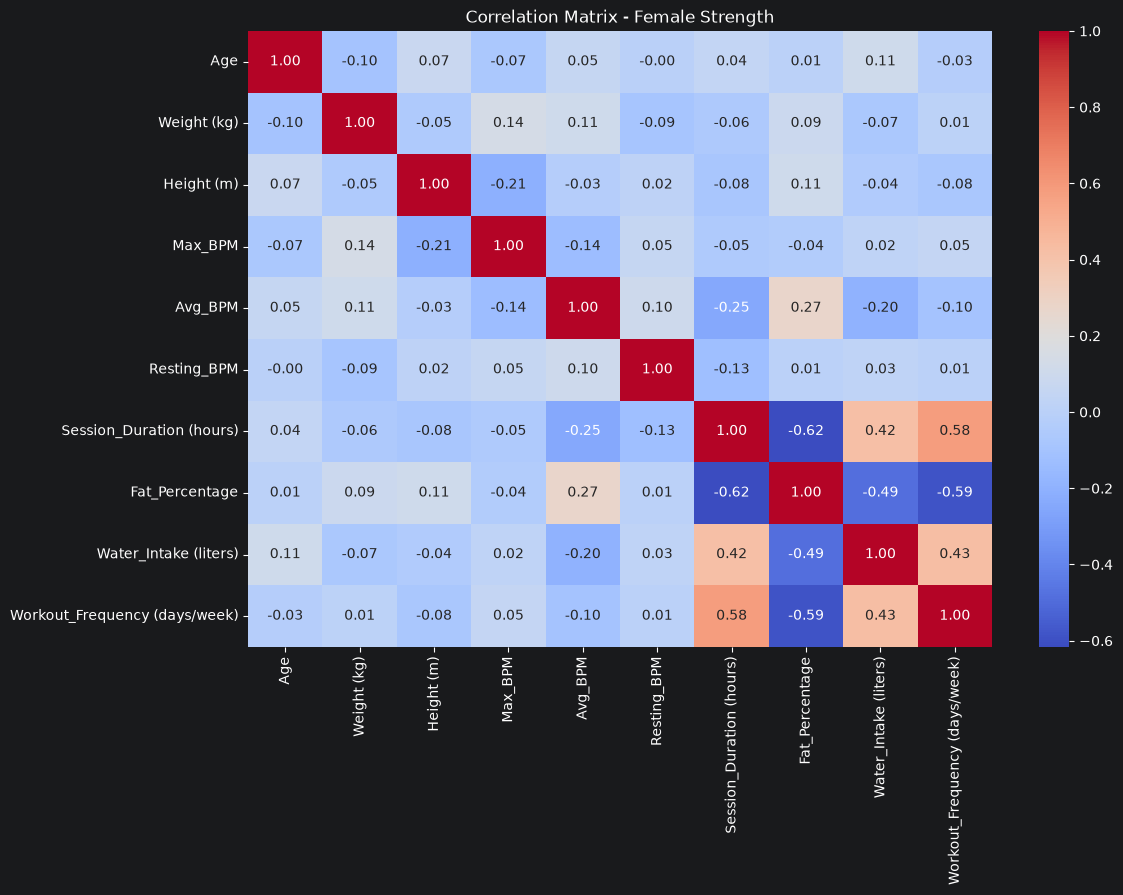

In [9]:
corr_matrix = df_fs[features].corr()

plt.figure(figsize=(12, 8))
sb.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix - Female Strength')
plt.show()

In [10]:
#Nema znacajnih korelacija,sve promenljive ostaju

In [11]:
#2.3 Outlieri

In [12]:
Q1 = df_fs[features].quantile(0.25)
Q3 = df_fs[features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_lower = (df_fs[features] < lower_bound).sum()
outliers_upper = (df_fs[features] > upper_bound).sum()

outliers_df = pd.DataFrame({
    'Donji outlieri': outliers_lower,
    'Gornji outlieri': outliers_upper,
    'Ukupno': outliers_lower + outliers_upper
})

print(outliers_df)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                0       0
Fat_Percentage                              3                0       3
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [13]:
#3 donja outliera u fat percentage

In [14]:
column = 'Fat_Percentage'

print("Vrednosti donjih outliera:")
print(df_fs.loc[df_fs[column] < lower_bound[column], column].values)

for limit in np.arange(0.01, 0.09, 0.01):
    lower = df_fs[column].quantile(limit)
    upper = df_fs[column].quantile(1 - limit)

    n_outliers = (
        (df_fs[column] < lower_bound[column]) &
        (df_fs[column] < lower)
    ).sum()

    print(f"Limit {limit:.2f}: {n_outliers} donjih outliera")

Vrednosti donjih outliera:
[15.2 15.1 15.1]
Limit 0.01: 2 donjih outliera
Limit 0.02: 3 donjih outliera
Limit 0.03: 3 donjih outliera
Limit 0.04: 3 donjih outliera
Limit 0.05: 3 donjih outliera
Limit 0.06: 3 donjih outliera
Limit 0.07: 3 donjih outliera
Limit 0.08: 3 donjih outliera


In [15]:
from scipy.stats.mstats import winsorize

df_fs['Fat_Percentage'] = np.asarray(
    winsorize(df_fs['Fat_Percentage'].to_numpy(), limits=[0.02, 0])
)

In [16]:
Q1 = df_fs[features].quantile(0.25)
Q3 = df_fs[features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_df = pd.DataFrame({
    'Donji outlieri': (df_fs[features] < lower_bound).sum(),
    'Gornji outlieri': (df_fs[features] > upper_bound).sum()
})

outliers_df['Ukupno'] = outliers_df.sum(axis=1)

print(outliers_df)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                0       0
Fat_Percentage                              3                0       3
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [17]:
print("Donja IQR granica:", lower_bound['Fat_Percentage'])

print("Preostali outlieri:")
print(
    df_fs.loc[
        df_fs['Fat_Percentage'] < lower_bound['Fat_Percentage'],
        'Fat_Percentage'
    ].values
)

Donja IQR granica: 15.974999999999996
Preostali outlieri:
[15.2 15.2 15.2]


In [18]:
from scipy.stats.mstats import winsorize

for limit in np.arange(0.01, 0.11, 0.01):
    temp = df_fs['Fat_Percentage'].copy()

    temp = pd.Series(
        np.asarray(winsorize(temp.to_numpy(), limits=[limit, 0]))
    )

    Q1_temp = temp.quantile(0.25)
    Q3_temp = temp.quantile(0.75)
    IQR_temp = Q3_temp - Q1_temp

    lower_temp = Q1_temp - 1.5 * IQR_temp

    n_outliers = (temp < lower_temp).sum()

    print(f"Limit {limit:.2f}: {n_outliers} outliera")

Limit 0.01: 3 outliera
Limit 0.02: 3 outliera
Limit 0.03: 0 outliera
Limit 0.04: 0 outliera
Limit 0.05: 0 outliera
Limit 0.06: 0 outliera
Limit 0.07: 0 outliera
Limit 0.08: 0 outliera
Limit 0.09: 0 outliera
Limit 0.10: 0 outliera


In [19]:
#Za limit od 0.03 imace 0 outliera

In [20]:
from scipy.stats.mstats import winsorize

df_fs['Fat_Percentage'] = np.asarray(
    winsorize(
        df.loc[df_fs.index, 'Fat_Percentage'].to_numpy().copy(),
        limits=[0.03, 0]
    )
)

In [21]:
from scipy.stats.mstats import winsorize

for limit in np.arange(0.01, 0.11, 0.01):
    temp = df_fs['Fat_Percentage'].copy()

    temp = pd.Series(
        np.asarray(winsorize(temp.to_numpy(), limits=[limit, 0]))
    )

    Q1_temp = temp.quantile(0.25)
    Q3_temp = temp.quantile(0.75)
    IQR_temp = Q3_temp - Q1_temp

    lower_temp = Q1_temp - 1.5 * IQR_temp

    n_outliers = (temp < lower_temp).sum()

    print(f"Limit {limit:.2f}: {n_outliers} outliera")

Limit 0.01: 0 outliera
Limit 0.02: 0 outliera
Limit 0.03: 0 outliera
Limit 0.04: 0 outliera
Limit 0.05: 0 outliera
Limit 0.06: 0 outliera
Limit 0.07: 0 outliera
Limit 0.08: 0 outliera
Limit 0.09: 0 outliera
Limit 0.10: 0 outliera


In [22]:
#Sad smo dosli do 0 outliera pa prelazimo na skaliranej

In [23]:
#2.4 MinMax skaliranje

In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_fs = scaler.fit_transform(df_fs[features])

X_fs = pd.DataFrame(
    X_fs,
    columns=features,
    index=df_fs.index
)

print("Minimalne vrednosti:")
print(X_fs.min())

print("\nMaksimalne vrednosti:")
print(X_fs.max())

Minimalne vrednosti:
Age                              0.0
Weight (kg)                      0.0
Height (m)                       0.0
Max_BPM                          0.0
Avg_BPM                          0.0
Resting_BPM                      0.0
Session_Duration (hours)         0.0
Fat_Percentage                   0.0
Water_Intake (liters)            0.0
Workout_Frequency (days/week)    0.0
dtype: float64

Maksimalne vrednosti:
Age                              1.0
Weight (kg)                      1.0
Height (m)                       1.0
Max_BPM                          1.0
Avg_BPM                          1.0
Resting_BPM                      1.0
Session_Duration (hours)         1.0
Fat_Percentage                   1.0
Water_Intake (liters)            1.0
Workout_Frequency (days/week)    1.0
dtype: float64


In [25]:
## 3. Određivanje optimalnog K

### 3.1. Elbow metoda

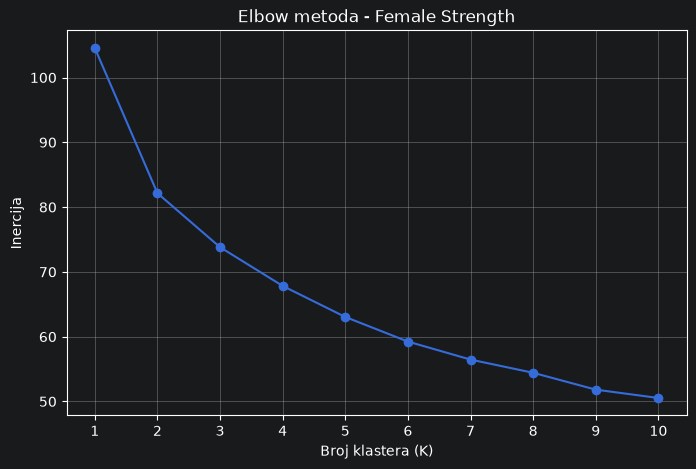

In [26]:
from sklearn.cluster import KMeans

inertias = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_fs)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertias, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Inercija')
plt.title('Elbow metoda - Female Strength')
plt.xticks(K)
plt.grid(True)
plt.show()


In [27]:
for k, inertia in zip(K, inertias):
    print(f"K={k}: Inercija={inertia:.2f}")

K=1: Inercija=104.56
K=2: Inercija=82.15
K=3: Inercija=73.81
K=4: Inercija=67.83
K=5: Inercija=63.04
K=6: Inercija=59.24
K=7: Inercija=56.46
K=8: Inercija=54.42
K=9: Inercija=51.82
K=10: Inercija=50.53


In [28]:
#Vidimo da je opet najznacajniji pad kod K=2,s toga uzimamo k=2

In [29]:
### 3.2. Silhouette metoda

K=2: Silhouette=0.2551
K=3: Silhouette=0.1476
K=4: Silhouette=0.1452
K=5: Silhouette=0.1456
K=6: Silhouette=0.1489
K=7: Silhouette=0.1465
K=8: Silhouette=0.1221
K=9: Silhouette=0.1246
K=10: Silhouette=0.1371


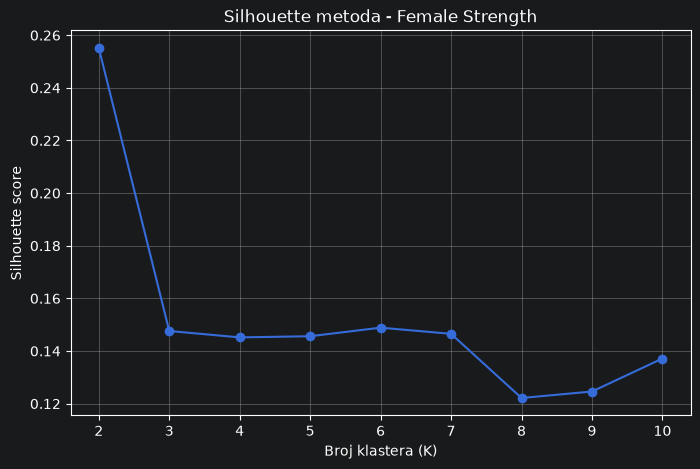

In [30]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_fs)
    score = silhouette_score(X_fs, labels)

    silhouette_scores.append(score)
    print(f"K={k}: Silhouette={score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette metoda - Female Strength')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [31]:
#3.3 Dendrogrami

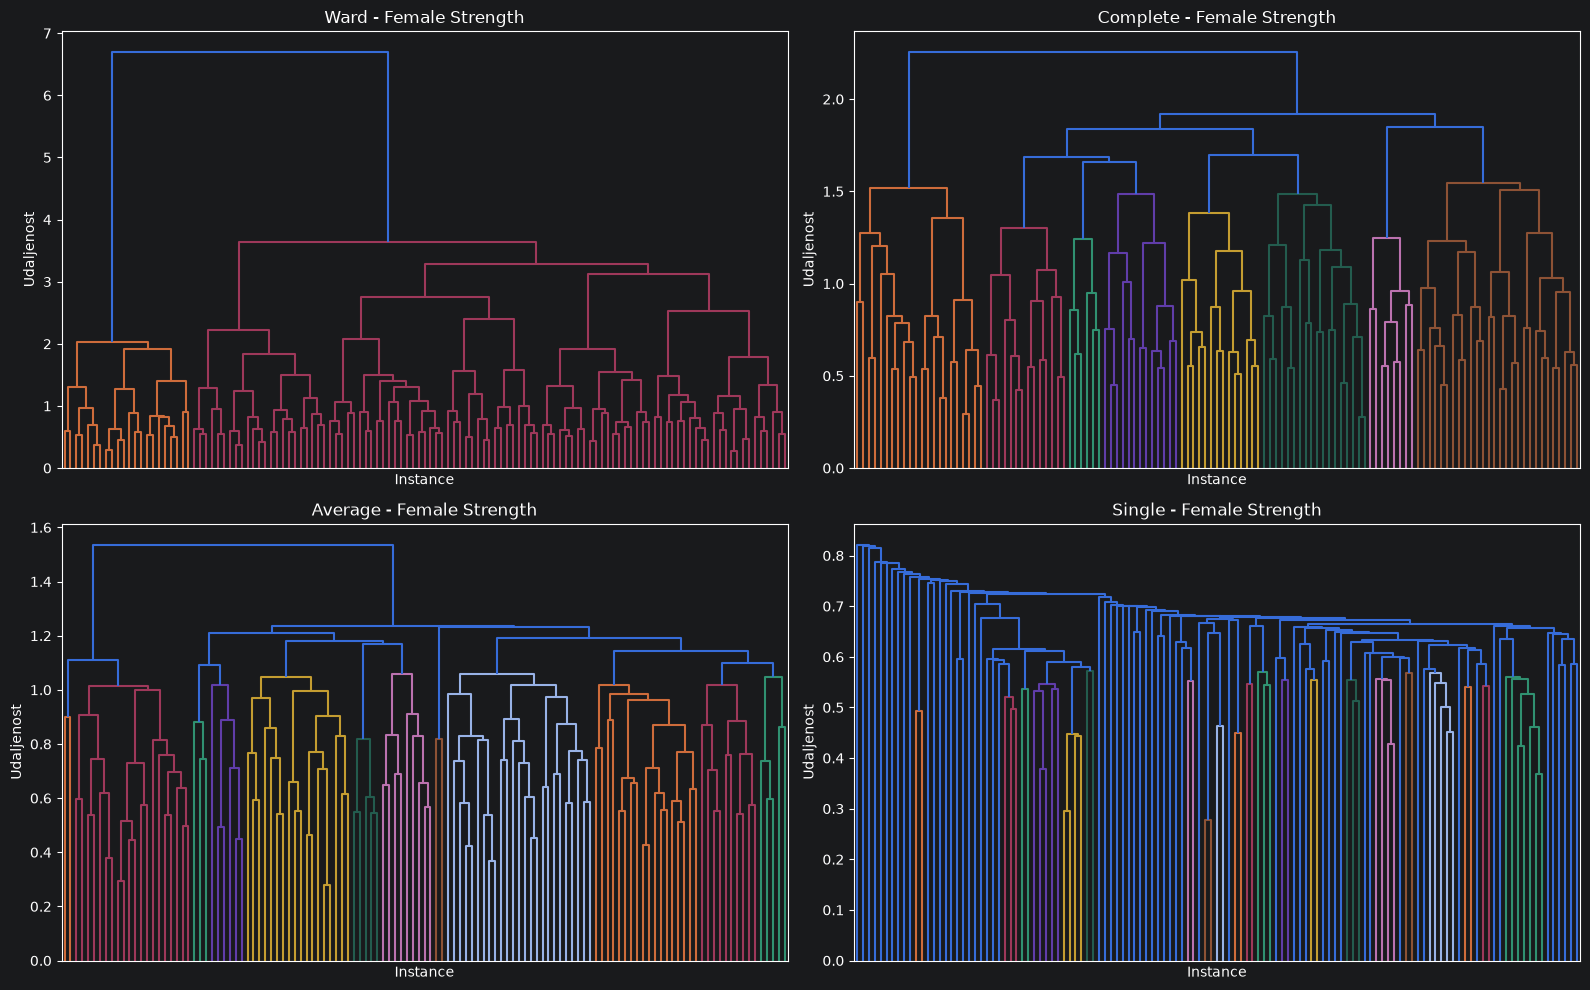

In [32]:
from scipy.cluster.hierarchy import linkage, dendrogram

methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, method in zip(axes.flatten(), methods):
    Z = linkage(X_fs, method=method)

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f'{method.capitalize()} - Female Strength')
    ax.set_xlabel('Instance')
    ax.set_ylabel('Udaljenost')

plt.tight_layout()
plt.show()

In [33]:
## 4. Klasterizacija i tumačenje klastera

### 4.1. KMeans klasterizacija i tumačenje klastera

In [34]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df_fs['Cluster_KMeans'] = kmeans.fit_predict(X_fs)

print("Broj instanci po klasterima:")
print(df_fs['Cluster_KMeans'].value_counts().sort_index())

print("\nSilhouette score:")
print(silhouette_score(X_fs, df_fs['Cluster_KMeans']))

Broj instanci po klasterima:
Cluster_KMeans
0    101
1     22
Name: count, dtype: int64

Silhouette score:
0.25514079731128647


In [35]:
#4.1.1. Tumačenje KMeans klastera

In [36]:
cluster_summary = df_fs.groupby('Cluster_KMeans')[
    features + ['Calories_Burned']
].mean().round(2)

print("Prosečne vrednosti atributa po klasterima:")
print(cluster_summary.to_string())

Prosečne vrednosti atributa po klasterima:
                  Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  Workout_Frequency (days/week)  Calories_Burned
Cluster_KMeans                                                                                                                                                                                
0               38.83        61.63        1.65   178.86   145.32        62.24                      1.17           30.43                   2.06                           3.06           801.45
1               38.27        60.10        1.62   179.86   133.55        60.68                      1.78           17.81                   2.70                           4.55          1146.14


In [37]:
#Klaster 0 ima krace treninge manju ucestalost treninga visi procenat masti i nizu prosecnu potrosnju kalorija i takodje mnogo je veci sa 101 instancom
#dok Klaster 1 ima dosta duze treninge vecu ucestalost,nizi procenat masti i vecu potrosnju klaroija
#Sad idemo na hijerarhijsku klasterizaciju

In [38]:
from sklearn.cluster import AgglomerativeClustering

methods = ['ward', 'complete', 'average', 'single']

for method in methods:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )

    labels = model.fit_predict(X_fs)

    print(f"\n===== {method.upper()} =====")
    print("Broj instanci po klasterima:")
    print(pd.Series(labels).value_counts().sort_index())
    print(f"Silhouette score: {silhouette_score(X_fs, labels):.4f}")


===== WARD =====
Broj instanci po klasterima:
0    101
1     22
Name: count, dtype: int64
Silhouette score: 0.2551

===== COMPLETE =====
Broj instanci po klasterima:
0    101
1     22
Name: count, dtype: int64
Silhouette score: 0.2551

===== AVERAGE =====
Broj instanci po klasterima:
0    101
1     22
Name: count, dtype: int64
Silhouette score: 0.2551

===== SINGLE =====
Broj instanci po klasterima:
0    122
1      1
Name: count, dtype: int64
Silhouette score: 0.0489


In [39]:
#Prve 3 metode daju sve isti rezultat ko kmeans dok single daje znatno losiji rezultat,pa cemo koristiti ward za analizu

In [40]:
ward = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

df_fs['Cluster_Ward'] = ward.fit_predict(X_fs)

ward_summary = df_fs.groupby('Cluster_Ward')[
    features + ['Calories_Burned']
].mean().round(2)

print("Prosečne vrednosti po Ward klasterima:")
print(ward_summary.to_string())

print("\nPoređenje KMeans i Ward klastera:")
print(pd.crosstab(
    df_fs['Cluster_KMeans'],
    df_fs['Cluster_Ward']
))

Prosečne vrednosti po Ward klasterima:
                Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  Workout_Frequency (days/week)  Calories_Burned
Cluster_Ward                                                                                                                                                                                
0             38.83        61.63        1.65   178.86   145.32        62.24                      1.17           30.43                   2.06                           3.06           801.45
1             38.27        60.10        1.62   179.86   133.55        60.68                      1.78           17.81                   2.70                           4.55          1146.14

Poređenje KMeans i Ward klastera:
Cluster_Ward      0   1
Cluster_KMeans         
0               101   0
1                 0  22


In [41]:
#Vidimo da su rezultati isti ko u Kmeans pa je tamo gore vec ista interpretacija klastera ko sto bi ovde bila,zavrsen je female strengh